# 7 · Explorar, representar incertidumbre y aprender con los datos disponibles

**Lectura acompañada:** §§7.1–7.8, pp. 173–198 de [Murphy, v5](https://arxiv.org/abs/2412.05265v5).

Este capítulo reúne preguntas que atraviesan los algoritmos anteriores. Las conectaremos con una pregunta práctica: ¿qué puede aprender el agente con la información y el presupuesto que tiene?

**Objetivo:** distinguir regret de recompensa, incertidumbre del mundo de incertidumbre del modelo, acciones de habilidades y aprendizaje online de offline. Necesitas probabilidad básica y los conceptos de valor y política. El código utiliza únicamente NumPy y Matplotlib.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEMILLA = 2026
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (8, 3.5), "axes.grid": True, "grid.alpha": 0.25})


## 1. §7.1 · Lo que cuesta aprender mientras actuamos

Una política final excelente puede haber desperdiciado muchas interacciones. El regret evalúa también ese recorrido. En un bandit con medias $\mu_t(a)$ mediremos

$$\mathcal R_T=\sum_{t=1}^T[\max_a\mu_t(a)-\mu_t(a_t)].$$

Es pseudorregret porque usa medias verdaderas, conocidas por el evaluador pero no por el agente. No resta realizaciones aleatorias de premios; cada término es no negativo.

Si cambia la mejor acción, este comparador puede cambiar con ella: es dinámico. Compararlo con la mejor acción fija durante todo el periodo definiría otra métrica. Las garantías de adaptación necesitan limitar de algún modo cuánto cambia el entorno; un adversario arbitrario puede hacer imposible aprender una buena predicción.

El regret bayesiano promedia sobre un prior de problemas. El criterio minimax mira el peor caso de una clase. Elegir uno es elegir qué tipo de incertidumbre o protección nos interesa.


In [2]:
medias_t = np.array([[0.2, 0.8], [0.2, 0.8], [0.8, 0.2], [0.8, 0.2]])
acciones = np.array([1, 1, 1, 1])
valor_elegido = medias_t[np.arange(len(acciones)), acciones].sum()
comparador_dinamico = medias_t.max(axis=1).sum()
comparador_fijo = medias_t.sum(axis=0).max()
print("Pseudorregret dinámico:", comparador_dinamico-valor_elegido)
print("Diferencia frente a mejor brazo fijo:", comparador_fijo-valor_elegido)


Pseudorregret dinámico: 1.2000000000000002
Diferencia frente a mejor brazo fijo: 0.0


La misma secuencia puede ser óptima frente al mejor brazo fijo y mala frente a uno que cambia a mitad. Ninguna cifra tiene sentido sin nombrar el comparador.

## 2. §7.2 · Optimismo y muestreo de modelos

$\epsilon$-greedy explora al azar una fracción de las veces. UCB suma a cada media una bonificación por incertidumbre, por ejemplo $\sqrt{2\log(t)/N(a)}$ en la forma elemental para recompensas acotadas.

Thompson sampling mantiene una distribución sobre modelos, muestrea uno y actúa como si fuese verdadero. Para recompensas Bernoulli y prior Beta(1,1), observar éxitos y fracasos actualiza sus dos parámetros. No confunde «este brazo tiene media alta» con «todavía no sé su media».

En MDP, PSRL muestrea un modelo y puede mantener una política coherente durante un episodio. Eso facilita exploración temporalmente consistente. Un bandit de un paso no permite demostrar esa ventaja de exploración profunda.


Medias posteriores: [0.6    0.6562]
Desviaciones sobre la media desconocida: [0.2    0.0827]


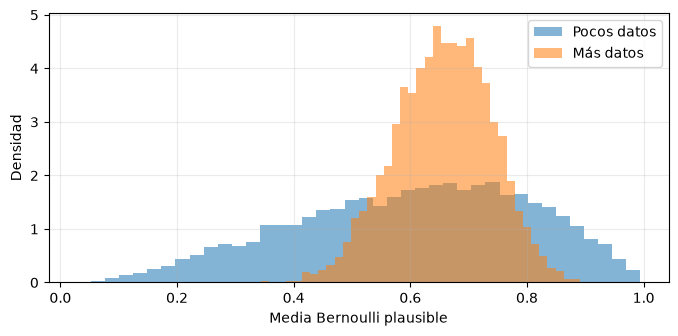

In [3]:
exitos = np.array([2, 20])
fracasos = np.array([1, 10])
alpha, beta = 1+exitos, 1+fracasos
media_posterior = alpha/(alpha+beta)
varianza_posterior = alpha*beta/((alpha+beta)**2*(alpha+beta+1))
print("Medias posteriores:", media_posterior)
print("Desviaciones sobre la media desconocida:", np.sqrt(varianza_posterior))
rng = np.random.default_rng(SEMILLA)
muestras = rng.beta(alpha, beta, size=(10000, 2))
plt.hist(muestras[:, 0], bins=40, alpha=0.55, density=True, label="Pocos datos")
plt.hist(muestras[:, 1], bins=40, alpha=0.55, density=True, label="Más datos")
plt.xlabel("Media Bernoulli plausible")
plt.ylabel("Densidad")
plt.legend()
plt.show()


## 3. Aprender en un mundo fijo y en uno que cambia

Cuatro brazos tienen medias 0.2, 0.4, 0.6 y 0.8. En el escenario cambiante invertimos el orden a mitad. El agente observa solo la recompensa de su acción.

Implementamos además Thompson con olvido: reducimos los pseudoconteos por encima del prior antes de incorporar el nuevo dato. Es una heurística adaptativa; ya no es el posterior exacto del modelo Bernoulli estacionario.

La simulación vectoriza réplicas, no comparte información entre agentes. El generador de recompensas está separado del de decisiones. Las mismas uniformes de recompensa permiten comparaciones con ruido común entre métodos; cada método sigue viendo exclusivamente su acción.


In [4]:
def simular(metodo, cambiante=False, seed=SEMILLA, replicas=16, pasos=2000, olvido=0.98):
    rng = np.random.default_rng(seed)
    ruido = np.random.default_rng(seed+100000)
    n = np.zeros((replicas, 4))
    suma = np.zeros_like(n)
    alpha, beta = np.ones_like(n), np.ones_like(n)
    regret = np.zeros((replicas, pasos))
    filas = np.arange(replicas)
    for t in range(pasos):
        mu = np.array([0.2, 0.4, 0.6, 0.8])
        if cambiante and t >= pasos//2:
            mu = mu[::-1]
        medias = np.divide(suma, n, out=np.zeros_like(n), where=n>0)
        if t < 4:
            a = np.full(replicas, t)
        elif metodo == "epsilon":
            a = (medias+rng.uniform(0, 1e-10, medias.shape)).argmax(axis=1)
            explorar = rng.random(replicas) < 0.1
            a[explorar] = rng.integers(0, 4, explorar.sum())
        elif metodo == "UCB":
            a = (medias+np.sqrt(2*np.log(t+1)/n)).argmax(axis=1)
        else:
            a = rng.beta(alpha, beta).argmax(axis=1)
        r = (ruido.random(replicas) < mu[a]).astype(float)
        n[filas, a] += 1
        suma[filas, a] += r
        if metodo == "Thompson con olvido":
            alpha = 1+olvido*(alpha-1)
            beta = 1+olvido*(beta-1)
        alpha[filas, a] += r
        beta[filas, a] += 1-r
        regret[:, t] = mu.max()-mu[a]
    return regret.cumsum(axis=1)


Antes de ejecutar, predice quién se beneficiará de olvidar. Después separa tres cosas: rendimiento en el entorno fijo, coste de adaptación tras el cambio y configuración concreta de cada algoritmo.


Cambio: False epsilon Regret final: 77.0
Cambio: False UCB Regret final: 86.39


Cambio: False Thompson Regret final: 14.66


Cambio: False Thompson con olvido Regret final: 151.73
Cambio: True epsilon Regret final: 585.19
Cambio: True UCB Regret final: 109.39
Cambio: True Thompson Regret final: 324.86


Cambio: True Thompson con olvido Regret final: 166.12


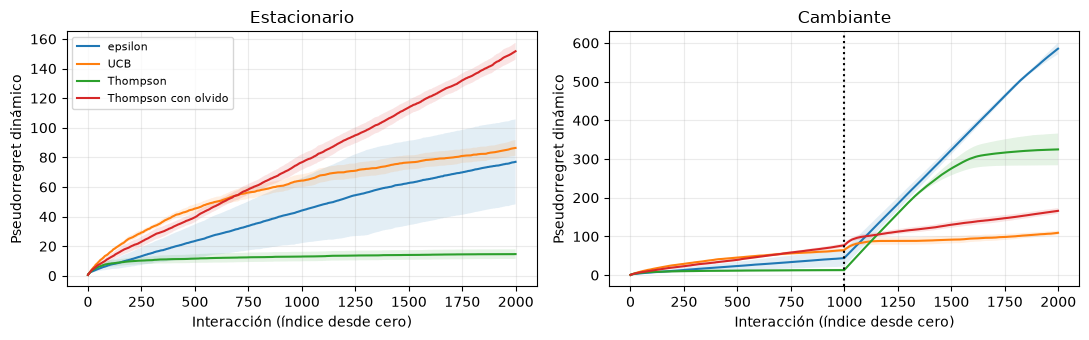

In [5]:
metodos = ["epsilon", "UCB", "Thompson", "Thompson con olvido"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, cambiante in zip(axes, [False, True]):
    for metodo in metodos:
        datos = simular(metodo, cambiante)
        assert np.all(np.diff(datos, axis=1) >= -1e-12)
        media = datos.mean(axis=0)
        banda = 1.96*datos.std(axis=0, ddof=1)/np.sqrt(len(datos))
        ax.plot(media, label=metodo)
        ax.fill_between(np.arange(len(media)), media-banda, media+banda, alpha=0.12)
        print("Cambio:", cambiante, metodo, "Regret final:", round(media[-1], 2))
    ax.set(title="Cambiante" if cambiante else "Estacionario",
           xlabel="Interacción (índice desde cero)", ylabel="Pseudorregret dinámico")
    if cambiante:
        ax.axvline(1000, color="black", linestyle=":")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()


Olvidar datos puede acelerar una adaptación y desperdiciar información estable. El resultado depende del momento del cambio, la separación de medias y el factor de olvido. No hay aquí evidencia de un ganador universal, ni un benchmark de RL secuencial completo.

## 4. §7.3 · La media no cuenta toda la historia

RL distribucional modela la distribución del retorno, mediante masas categóricas, cuantiles u otras representaciones. Dos acciones pueden tener la misma esperanza y riesgos diferentes.

Esto no equivale a incertidumbre epistémica sobre la media. Si sabemos exactamente que una moneda produce −10 o 10, el retorno sigue siendo variable aunque no ignoremos nada del modelo.

Construimos dos distribuciones de media exactamente cero y comparamos su peor cola. El CVaR inferior se interpreta aquí como la media del 10% de retornos más bajos de una distribución empírica; maximizarlo expresaría un criterio de aversión al riesgo distinto de maximizar la esperanza.


Seguro media: 0.0 desv: 0.0 media peor 10%: 0.0
Variable media: 0.0 desv: 10.0 media peor 10%: -10.0


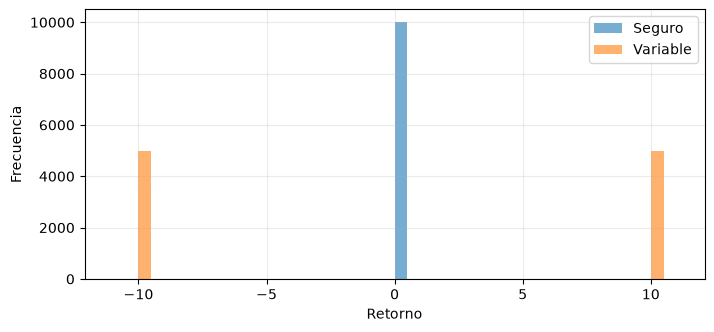

In [6]:
seguro = np.zeros(10000)
variable = np.tile([-10.0, 10.0], 5000)

def cola_inferior(datos, fraccion=0.1):
    cantidad = max(1, int(len(datos)*fraccion))
    return np.sort(datos)[:cantidad].mean()

for nombre, datos in [("Seguro", seguro), ("Variable", variable)]:
    print(nombre, "media:", datos.mean(), "desv:", datos.std(),
          "media peor 10%:", cola_inferior(datos))
plt.hist(seguro, bins=np.linspace(-11, 11, 45), alpha=0.6, label="Seguro")
plt.hist(variable, bins=np.linspace(-11, 11, 45), alpha=0.6, label="Variable")
plt.xlabel("Retorno")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()


No hemos entrenado un algoritmo distribucional: hemos mostrado qué información adicional tendría que representar y por qué una sola media no la contiene.

## 5. §7.4 · Curiosidad útil frente a ruido irreducible

La motivación intrínseca añade señales de novedad, sorpresa o aprendizaje. Bonos de conteo, RND, ganancia de información y empowerment no miden exactamente lo mismo. Los currículos y Go-Explore organizan qué experiencias buscar.

El ejemplo de una televisión ruidosa muestra el peligro de premiar solo error de predicción. Si cada imagen es ruido independiente, siempre será difícil predecirla aunque observar más no revele estructura útil.

Para una media desconocida con prior normal de varianza 1 y observaciones de varianza 1, la varianza posterior es $1/(1+n)$. Su reducción mide aprendizaje sobre la media. Un predictor de ruido conocido mantiene error cuadrático esperado 1 indefinidamente.


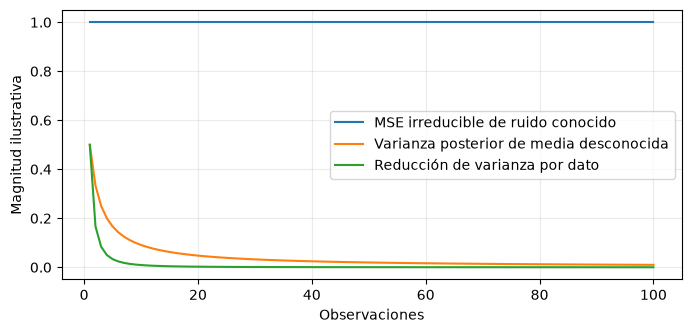

In [7]:
n = np.arange(1, 101)
incertidumbre_media = 1/(1+n)
ganancia_varianza = 1/n - 1/(1+n)
plt.plot(n, np.ones_like(n), label="MSE irreducible de ruido conocido")
plt.plot(n, incertidumbre_media, label="Varianza posterior de media desconocida")
plt.plot(n, ganancia_varianza, label="Reducción de varianza por dato")
plt.xlabel("Observaciones")
plt.ylabel("Magnitud ilustrativa")
plt.legend()
plt.show()


Las tres curvas miden cantidades distintas; no deben sumarse como si fueran premios intercambiables sin diseñar el objetivo. Su contraste ayuda a separar incertidumbre reducible de aleatoriedad permanente.

## 6. §7.5 · Una habilidad dura más que una acción

Una opción define dónde puede empezar, qué política ejecuta y cuándo termina. El agente superior decide entre habilidades. Si una opción dura $\tau$ pasos, su objetivo incluye

$$\sum_{k=0}^{\tau-1}\gamma^k r_{t+k}+\gamma^\tau V(s_{t+\tau}).$$

Usar $\gamma$ en el último término como si hubiese pasado un solo paso sobrevalora la continuación. Option-critic, MAXQ y jerarquías feudales distribuyen decisiones y crédito de maneras distintas. Descubrir subtareas puede reducir dificultad y también restringir soluciones si las habilidades disponibles son malas.


In [8]:
gamma = 0.9
premios_opcion = np.array([0.0, 0.0, 1.0])
valor_al_terminar = 2.0
duracion = len(premios_opcion)
correcto = np.dot(gamma**np.arange(duracion), premios_opcion) + gamma**duracion*valor_al_terminar
incorrecto = np.dot(gamma**np.arange(duracion), premios_opcion) + gamma*valor_al_terminar
print("Objetivo con duración:", correcto, "Ignorando duración:", incorrecto)
assert correcto < incorrecto


Objetivo con duración: 2.2680000000000002 Ignorando duración: 2.6100000000000003


## 7. §7.6 · Imitar acciones y corregir el cambio de distribución

Behavior cloning aprende acciones a partir de demostraciones. En decisiones independientes se parece a clasificación. En una secuencia, un pequeño error puede llevar a un estado que nunca apareció en los ejemplos, y desde allí producir más errores.

La siguiente cuenta solo ilustra la probabilidad de cometer al menos un error si los fallos fueran independientes con probabilidad constante $\epsilon$. No es una cota general del coste secuencial, donde esa independencia puede fallar.


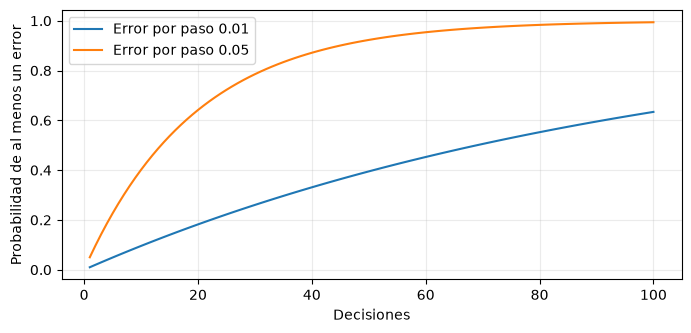

In [9]:
horizontes = np.arange(1, 101)
for epsilon in [0.01, 0.05]:
    plt.plot(horizontes, 1-(1-epsilon)**horizontes, label=f"Error por paso {epsilon}")
plt.xlabel("Decisiones")
plt.ylabel("Probabilidad de al menos un error")
plt.legend()
plt.show()


DAgger recoge estados visitados por el aprendiz y pide acciones al experto para ampliar el conjunto. Requiere interacción y acceso a etiquetas; no es una solución puramente offline.

IRL intenta inferir una recompensa compatible con el experto, pero normalmente no hay una única. GAIL y AIRL utilizan ideas adversarias para comparar ocupaciones o aprender estructuras relacionadas con recompensas. Imitar la distribución de acciones de una sola observación no equivale a igualar toda la distribución de trayectorias.

## 8. §7.7 · Qué no puede decirnos un dataset fijo

En offline RL no podemos probar acciones nuevas mientras aprendemos. Un valor alto para una acción ausente puede ser un artefacto de extrapolación. Optimizarlo agresivamente empeora la situación.

Considera datos que solo contienen la acción 0, con media 0.6. Dos mundos, uno donde la acción 1 vale 0 y otro donde vale 1, producen exactamente los mismos datos observados. Ningún algoritmo puede identificar cuál es real sin supuestos o información adicional.


In [10]:
mundos = {"Acción ausente mala": np.array([0.6, 0.0]),
          "Acción ausente buena": np.array([0.6, 1.0])}
for nombre, medias in mundos.items():
    print(nombre, "media observada:", medias[0], "acción realmente óptima:", medias.argmax())
assert mundos["Acción ausente mala"][0] == mundos["Acción ausente buena"][0]


Acción ausente mala media observada: 0.6 acción realmente óptima: 0
Acción ausente buena media observada: 0.6 acción realmente óptima: 1


Una penalización conservadora puede evitar asignar valores altos sin evidencia. En una versión mínima del término de CQL, añadimos

$$\alpha[\log\sum_a e^{Q(a)}-\mathbb E_{a\sim D}Q(a)]$$

a un error de ajuste. Si el dataset solo elige la acción 0, el gradiente del término es softmax(Q) menos su vector indicador. El siguiente bandit elimina el bootstrap para aislar ese efecto.


In [11]:
def ajuste_offline(alpha, pasos=400):
    Q = np.array([0.0, 2.0])  # La acción ausente empieza con una estimación optimista.
    for _ in range(pasos):
        probabilidades = np.exp(Q-Q.max())
        probabilidades /= probabilidades.sum()
        grad = np.array([Q[0]-0.6, 0.0]) + alpha*(probabilidades-np.array([1.0, 0.0]))
        Q -= 0.05*grad
    return Q

for alpha in [0.0, 1.0]:
    Q = ajuste_offline(alpha)
    print("Penalización:", alpha, "Q:", Q, "Acción elegida:", Q.argmax())


Penalización: 0.0 Q: [0.6 2. ] Acción elegida: 1
Penalización: 1.0 Q: [ 0.6669 -2.0328] Acción elegida: 0


Ser conservador limita un riesgo, pero puede renunciar a una acción ausente que sería excelente. La falta de información no desaparece. Las restricciones de política, modelos con incertidumbre y técnicas offline basadas en dinámica afrontan el mismo problema desde diferentes aproximaciones.

Decision Transformer y otros modelos de trayectorias condicionan decisiones a retornos deseados. Observar que una acción aparece en trayectorias exitosas no garantiza que cause el éxito en un mundo estocástico. Offline-to-online permite añadir experiencia posteriormente y revisar esas incertidumbres.

## 9. §7.8 · Agentes generales y límites de computación

AIXI combina una distribución universal sobre programas con planificación como ideal matemático. Su mezcla universal no es computable en la forma ideal y su planificación resulta inabordable en general. No lo convertimos en un algoritmo ejecutable con unas líneas de Python.

Su utilidad en esta lectura es recordar que información, memoria y cómputo son recursos del agente. Un objetivo formal no especifica por sí solo cómo alcanzarlo con un presupuesto finito. Las aproximaciones prácticas necesitan supuestos que restringen el mundo o las políticas.

## 10. Ejercicio: elegir cuánto olvidar

Cambia el factor de olvido. Cerca de uno se conservan datos durante más tiempo; valores menores reaccionan más deprisa y pueden aumentar la incertidumbre sostenida. Compara ambos escenarios con el mismo presupuesto.


In [12]:
for olvido in [0.90, 0.98, 0.995]:
    valores = []
    for cambio in [False, True]:
        datos = simular("Thompson con olvido", cambio, olvido=olvido, replicas=12)
        valores.append(datos[:, -1].mean())
    print(f"Olvido={olvido}: regret fijo={valores[0]:.2f}, cambiante={valores[1]:.2f}")


Olvido=0.9: regret fijo=335.22, cambiante=334.37


Olvido=0.98: regret fijo=154.05, cambiante=166.22


Olvido=0.995: regret fijo=67.20, cambiante=103.68


<details>
<summary>Solución orientativa</summary>

Olvidar rápido facilita descartar una historia obsoleta, pero impide concentrar mucho la estimación en un mundo estable. No elijas el hiperparámetro ganador y luego presentes esa misma evaluación como confirmación independiente. Reserva semillas o escenarios nuevos.

Como segundo ejercicio, explica por qué la penalización offline no puede certificar cuál de los dos mundos de la sección 8 es real. La respuesta debe hablar de información ausente, no solo de qué algoritmo prefieres.

</details>

**Fuente:** adaptación de [Murphy, capítulo 7](https://arxiv.org/html/2412.05265v5#Ch7), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Ejemplos propios. [Resumen y experimento de referencia](../docs/07_otros_temas.md).
